In [1]:
import pandas as pd
import os

# Define file paths
data_dir = "../data"
files = {
    "chromium": "01-chromium-feature-flags.csv",
    "gitlab": "01-gitlab-feature-flags.csv",
    "kubernetes": "01-kubernetes-feature-gates.csv",
    "vespa": "01-vespa-feature-flags.csv"
}

# Read CSVs
dfs = {}
for system, filename in files.items():
    file_path = os.path.join(data_dir, filename)
    if os.path.exists(file_path):
        # GitLab milestones must stay text, otherwise 18.10 is read as 18.1
        dtype = {"milestone": str} if system == "gitlab" else None
        dfs[system] = pd.read_csv(file_path, dtype=dtype)
        print(f"Loaded {system}: {len(dfs[system])} rows")
    else:
        print(f"Warning: {filename} not found")

# Display first few rows of one as example
if "chromium" in dfs:
    display(dfs["chromium"].head())

Loaded chromium: 1896 rows
Loaded gitlab: 407 rows
Loaded kubernetes: 211 rows
Loaded vespa: 145 rows


,flag_name,has_expiration,expiry_milestone,is_never_expire,expiration_status,owners,owner_count
0,aaudio-per-stream-device-selection,True,150,False,Has Expiration,mjel@google.com;lt-web-apps-team@google.com,2
1,accessible-pdf-form,True,110,False,Has Expiration,bravi@microsoft.com;mohitb@microsoft.com,2
2,account-storage-prefs-themes-search-engines,True,138,False,Has Expiration,ankushkush@google.com;chrome-sync-dev@google.com,2
3,ack-copy-output-request-early-for-view-transition,True,150,False,Has Expiration,hitawala@chromium.org;vasilyt@chromium.org;jon...,3
4,adaptive-button-in-top-toolbar-page-summary,True,140,False,Has Expiration,salg@google.com;chrome-segmentation-platform@g...,2


In [2]:
# Reference point T0 of each system (Table 1). These are the analysed commits, so the
# notebook does not need the codebases themselves.
info_df = pd.DataFrame([
    {'System': 'Chromium', 'Version': 'M145', 'Commit': '54e2a84', 'Date': '2025-12-14'},
    {'System': 'GitLab', 'Version': 'v18.10', 'Commit': 'f3114f7', 'Date': '2026-02-26'},
    {'System': 'Kubernetes', 'Version': 'v1.36', 'Commit': 'c180d67', 'Date': '2025-12-12'},
    {'System': 'Vespa', 'Version': 'v8.620.35', 'Commit': 'f2f0d37', 'Date': '2025-12-22'},
])
display(info_df)

current_milestone_ch = 145                     # Chromium milestone
current_release_num = 1.36                     # Kubernetes minor release
current_date = pd.Timestamp('2025-12-22')      # Vespa commit date (Vespa deadlines are dates)

,System,Version,Commit,Date
0,Chromium,M145,54e2a84,2025-12-14
1,GitLab,v18.10,f3114f7,2026-02-26
2,Kubernetes,v1.36,c180d67,2025-12-12
3,Vespa,v8.620.35,f2f0d37,2025-12-22


In [3]:
# Count expiration metadata
results = []

# Helper to extract GitLab flag type from definition_file path
def _extract_gl_type(path):
    try:
        parts = str(path).split('/')
        for i, p in enumerate(parts):
            if p == 'feature_flags' and i + 1 < len(parts):
                return parts[i + 1]
    except:
        pass
    return 'unknown'

# GitLab types with a documented maximum lifespan
GL_TYPES_WITH_EXPIRATION = {'gitlab_com_derisk', 'wip', 'beta', 'experiment'}

for system, df in dfs.items():
    total = len(df)
    has_expiration = 0
    permanent = 0
    
    if system == "chromium":
        # Check 'has_expiration' column (string "True"/"False")
        if "has_expiration" in df.columns:
            has_expiration = df["has_expiration"].astype(str).str.lower().eq("true").sum()
        # Check 'is_never_expire' column
        if "is_never_expire" in df.columns:
            permanent = df["is_never_expire"].astype(str).str.lower().eq("true").sum()
            
    elif system == "kubernetes":
        # Check 'has_expiration' column (boolean or string)
        if "has_expiration" in df.columns:
            has_expiration = df["has_expiration"].astype(str).str.lower().eq("true").sum()
            
    elif system == "vespa":
        # Check 'is_permanent' column. If False, it has expiration.
        if "is_permanent" in df.columns:
            has_expiration = df["is_permanent"].astype(str).str.lower().eq("false").sum()
            permanent = df["is_permanent"].astype(str).str.lower().eq("true").sum()
            
    elif system == "gitlab":
        # Flags in directories with a documented max lifespan count as "With Expiration"
        # (gitlab_com_derisk: 2 mo, wip: 4 mo, beta: 6 mo, experiment: 6 mo)
        # The rest (ops, worker, development, undefined) have no defined expiration
        flag_types = df['definition_file'].apply(_extract_gl_type)
        has_expiration = flag_types.isin(GL_TYPES_WITH_EXPIRATION).sum()
        # No flags are "Permanent" — ops/worker/development/undefined have
        # no documented permanent nature, just no defined lifespan
        permanent = 0
        
    # Flags with no expiration info (neither expiring nor permanent)
    no_info = total - has_expiration - permanent
    
    results.append({
        "System": system.capitalize(),
        "Total Flags": total,
        "With Expiration": has_expiration,
        "Permanent": permanent,
        "No Expiration Info": no_info,
        "% With Expiration": round((has_expiration / total * 100), 1) if total > 0 else 0
    })

# Create summary dataframe
summary_df = pd.DataFrame(results)
display(summary_df)

,System,Total Flags,With Expiration,Permanent,No Expiration Info,% With Expiration
0,Chromium,1896,1752,144,0,92.4
1,Gitlab,407,198,0,209,48.6
2,Kubernetes,211,50,0,161,23.7
3,Vespa,145,53,92,0,36.6


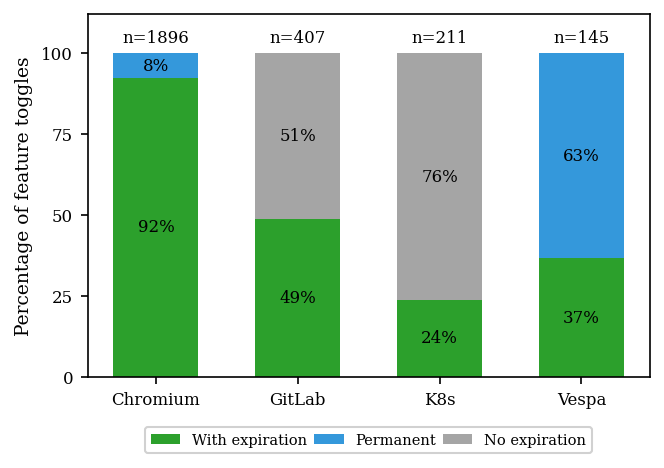

Chart saved to ../assets/rq1-expiration-adoption.pdf and .png


In [4]:
# RQ1 Chart: Adoption of Expiration Metadata (for paper - single column, vertical)
import matplotlib.pyplot as plt
import numpy as np

# Publication-quality style for single column
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})

# Prepare data from summary_df
systems = summary_df['System'].tolist()
totals = summary_df['Total Flags'].tolist()
with_exp = summary_df['With Expiration'].tolist()
permanent = summary_df['Permanent'].tolist()
no_info = summary_df['No Expiration Info'].tolist()

# Use shorter names for systems
short_names = {'Chromium': 'Chromium', 'Gitlab': 'GitLab', 'Kubernetes': 'K8s', 'Vespa': 'Vespa'}
systems_short = [short_names.get(s, s) for s in systems]

# Colors matching the study theme
colors = {
    'With Expiration': '#2ca02c',    # Green
    'Permanent': '#3498db',           # Blue  
    'No Expiration Info': '#A5A5A5'   # Gray
}

# Create stacked VERTICAL bar chart - same size as companion chart
fig, ax = plt.subplots(figsize=(4.5, 3.2))

x_pos = np.arange(len(systems))
bar_width = 0.6

# Normalize to 100% stacked bars for better comparison
totals_arr = np.array(totals)
with_exp_pct = np.array(with_exp) / totals_arr * 100
permanent_pct = np.array(permanent) / totals_arr * 100
no_info_pct = np.array(no_info) / totals_arr * 100

# Stack bars vertically
bars1 = ax.bar(x_pos, with_exp_pct, bar_width, label='With expiration', color=colors['With Expiration'])
bars2 = ax.bar(x_pos, permanent_pct, bar_width, bottom=with_exp_pct, label='Permanent', color=colors['Permanent'])
bars3 = ax.bar(x_pos, no_info_pct, bar_width, bottom=with_exp_pct + permanent_pct, label='No expiration', color=colors['No Expiration Info'])

# Add percentage labels on bars
for i, (w, p, n, t) in enumerate(zip(with_exp_pct, permanent_pct, no_info_pct, totals)):
    # With Expiration percentage
    if w > 12:  # Only show if segment is tall enough
        ax.text(i, w/2, f'{w:.0f}%', ha='center', va='center', fontsize=8, color='black')
    elif w > 0:  # Small segment - show to the side
        ax.text(i + 0.35, w/2, f'{w:.0f}%', ha='left', va='center', fontsize=7, color='black')
    # Permanent percentage - lower threshold to 7 so 8% shows inside
    if p > 7:
        ax.text(i, w + p/2, f'{p:.0f}%', ha='center', va='center', fontsize=8, color='black')
    elif p > 0:
        ax.text(i + 0.35, w + p/2, f'{p:.0f}%', ha='left', va='center', fontsize=7, color='black')
    # No Info percentage
    if n > 12:
        ax.text(i, w + p + n/2, f'{n:.0f}%', ha='center', va='center', fontsize=8, color='black')
    # Total count on top
    ax.text(i, 102, f'n={t}', ha='center', va='bottom', fontsize=8, color='black')

ax.set_xticks(x_pos)
ax.set_xticklabels(systems_short)
ax.set_ylabel('Percentage of feature toggles')
ax.set_ylim(0, 112)
ax.set_yticks([0, 25, 50, 75, 100])

# Legend at bottom, horizontal
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, framealpha=0.9, columnspacing=0.5)

plt.tight_layout()
plt.savefig('../assets/rq1-expiration-adoption.pdf', bbox_inches='tight')
plt.savefig('../assets/rq1-expiration-adoption.png', bbox_inches='tight')
plt.show()

print("Chart saved to ../assets/rq1-expiration-adoption.pdf and .png")

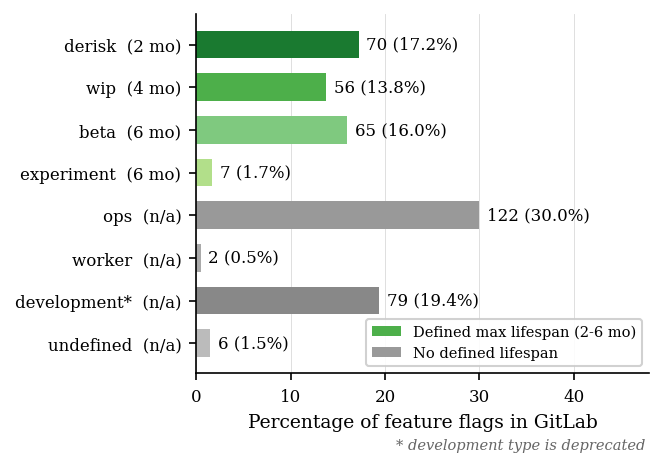


GitLab flag type summary (total=407):
  gitlab_com_derisk     max lifespan: 2 mo          count:  70  (17.2%)
  wip                   max lifespan: 4 mo          count:  56  (13.8%)
  beta                  max lifespan: 6 mo          count:  65  (16.0%)
  experiment            max lifespan: 6 mo          count:   7  (1.7%)
  ops                   max lifespan: n/a           count: 122  (30.0%)
  worker                max lifespan: n/a           count:   2  (0.5%)
  development           max lifespan: n/a           count:  79  (19.4%)
  undefined             max lifespan: n/a           count:   6  (1.5%)

With defined max lifespan (2-6 mo): 198 (48.6%)
No defined lifespan:                209 (51.4%)

Chart saved to ../assets/rq1-gitlab-categories.pdf and .png


In [5]:
# RQ1 Companion: GitLab Feature Flag Types & Lifespans (for paper - single column)
# Based on official documentation: https://docs.gitlab.com/development/feature_flags/
#
# Type              | Max Lifespan       | Notes
# ------------------|--------------------|-----------------------------------
# gitlab_com_derisk | 2 months           | Short-lived, de-risk deployments
# wip               | 4 months           | Work in progress, transition to another type
# beta              | 6 months           | Not yet stable/performant
# experiment        | 6 months           | A/B testing on GitLab.com
# ops               | No defined lifespan| Long-lived operational flags (annual review)
# worker            | No defined lifespan| Special ops for Sidekiq workers
# development       | No defined lifespan| Deprecated in favor of derisk/wip/beta
# undefined         | No defined lifespan| Flags without standard YAML definitions

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})

# --- Extract GitLab flag types from the data ---
def extract_type_gl(path):
    try:
        parts = str(path).split('/')
        for i, p in enumerate(parts):
            if p == 'feature_flags' and i + 1 < len(parts):
                return parts[i + 1]
    except:
        pass
    return 'unknown'

df_gl_cat = dfs['gitlab'].copy()
df_gl_cat['flag_type'] = df_gl_cat['definition_file'].apply(extract_type_gl)
gl_total = len(df_gl_cat)
tc = df_gl_cat['flag_type'].value_counts()

# Define categories with official lifespan info, ordered by lifespan (short → long → no defined)
# Green shades = defined max lifespan (these map to "With Expiration" in the adoption chart)
# Gray shades  = no defined lifespan (these map to "No Expiration Info" in the adoption chart)
categories = [
    {'type': 'gitlab_com_derisk', 'label': 'derisk',       'lifespan': '2 mo',        'color': '#1a7a30', 'text_color': 'black'},
    {'type': 'wip',               'label': 'wip',          'lifespan': '4 mo',        'color': '#4daf4a', 'text_color': 'black'},
    {'type': 'beta',              'label': 'beta',         'lifespan': '6 mo',        'color': '#7fc97f', 'text_color': 'black'},
    {'type': 'experiment',        'label': 'experiment',   'lifespan': '6 mo',        'color': '#b2df8a', 'text_color': 'black'},
    {'type': 'ops',               'label': 'ops',          'lifespan': 'n/a',         'color': '#999999', 'text_color': 'black'},
    {'type': 'worker',            'label': 'worker',       'lifespan': 'n/a',         'color': '#aaaaaa', 'text_color': 'black'},
    {'type': 'development',       'label': 'development*', 'lifespan': 'n/a',         'color': '#888888', 'text_color': 'black'},
    {'type': 'undefined',         'label': 'undefined',    'lifespan': 'n/a',         'color': '#bbbbbb', 'text_color': 'black'},
]

for cat in categories:
    cat['count'] = int(tc.get(cat['type'], 0))
    cat['pct'] = cat['count'] / gl_total * 100

# --- Horizontal bar chart (single column width) ---
fig, ax = plt.subplots(figsize=(4.5, 3.2))

y_pos = np.arange(len(categories))[::-1]  # Reverse so shortest lifespan is at top
bar_height = 0.65

for j, cat in enumerate(categories):
    y = y_pos[j]
    bar = ax.barh(y, cat['pct'], bar_height, color=cat['color'])
    # Label outside bar to the right
    ax.text(cat['pct'] + 0.8, y, f"{cat['count']} ({cat['pct']:.1f}%)",
            ha='left', va='center', fontsize=8, color='black')

# Y-axis labels: type name + lifespan
y_labels = [f"{cat['label']}  ({cat['lifespan']})" for cat in categories]
ax.set_yticks(y_pos)
ax.set_yticklabels(y_labels)
ax.set_xlabel('Percentage of feature flags in GitLab')

# Light grid
ax.grid(axis='x', color='#d0d0d0', linestyle='-', linewidth=0.4, alpha=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, 48)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Grouped legend: only two groups now
legend_elements = [
    Patch(facecolor='#4daf4a', label=f'Defined max lifespan (2-6 mo)'),
    Patch(facecolor='#999999', label=f'No defined lifespan'),
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=0.9)

# Footnote about deprecated type
ax.text(0.99, -0.18, '* development type is deprecated', transform=ax.transAxes,
        fontsize=7, ha='right', va='top', style='italic', color='#666666')

#plt.title(f'GitLab Feature Flag Types (n={gl_total})', fontsize=9, pad=8)
plt.tight_layout()
plt.savefig('../assets/rq1-gitlab-categories.pdf', bbox_inches='tight')
plt.savefig('../assets/rq1-gitlab-categories.png', bbox_inches='tight')
plt.show()

print(f"\nGitLab flag type summary (total={gl_total}):")
for cat in categories:
    print(f"  {cat['type']:20s}  max lifespan: {cat['lifespan']:12s}  count: {cat['count']:3d}  ({cat['pct']:.1f}%)")
print(f"\nWith defined max lifespan (2-6 mo): {sum(c['count'] for c in categories[:4])} ({sum(c['pct'] for c in categories[:4]):.1f}%)")
print(f"No defined lifespan:                {sum(c['count'] for c in categories[4:])} ({sum(c['pct'] for c in categories[4:]):.1f}%)")
print("\nChart saved to ../assets/rq1-gitlab-categories.pdf and .png")

In [6]:
# GitLab Expiration Analysis based on type-specific maximum lifespans
# Policy (from gitlab/doc/development/feature_flags/_index.md):
#   gitlab_com_derisk: 2 months
#   wip: 4 months
#   beta: 6 months
#   experiment: 6 months
#   ops: Unlimited (annual review)
#   worker: Unlimited (special ops)
#   development/undefined: No documented maximum lifespan

import pandas as pd
import numpy as np

# Load GitLab data
df_gl = dfs['gitlab'].copy()

# Extract flag type from definition_file path
def extract_type(path):
    """Extract type from path like .../config/feature_flags/<type>/flag_name.yml"""
    try:
        parts = str(path).split('/')
        # Find 'feature_flags' in path and take the next element
        for i, p in enumerate(parts):
            if p == 'feature_flags' and i + 1 < len(parts):
                return parts[i + 1]
    except:
        pass
    return 'unknown'

df_gl['flag_type'] = df_gl['definition_file'].apply(extract_type)

# GitLab milestone arithmetic
# GitLab releases monthly, but the number of minor versions per major varies:
# Verified from release history (release dates + CHANGELOG):
#   10: 10.0–10.8  (9 releases)    14: 14.0–14.10 (11 releases)
#   11: 11.0–11.11 (12 releases)   15: 15.0–15.11 (12 releases)
#   12: 12.0–12.10 (11 releases)   16: 16.0–16.11 (12 releases)
#   13: 13.0–13.12 (13 releases)   17: 17.0–17.11 (12 releases)
#                                   18: 18.0–18.11 (12 releases)
GITLAB_MAX_MINOR = {
    10: 8, 11: 11, 12: 10, 13: 12, 14: 10,
    15: 11, 16: 11, 17: 11, 18: 11, 19: 11
}
_MIN_MAJOR = min(GITLAB_MAX_MINOR)

def milestone_to_months(ms):
    """Convert 'major.minor' to a sequential milestone index,
    accounting for the actual number of minor versions per major."""
    try:
        parts = str(ms).split('.')
        major = int(parts[0])
        minor = int(parts[1])
        seq = 0
        for m in range(_MIN_MAJOR, major):
            seq += GITLAB_MAX_MINOR.get(m, 11) + 1
        seq += minor
        return seq
    except:
        return None

def months_to_milestone(seq):
    """Convert sequential index back to 'major.minor'."""
    for major in sorted(GITLAB_MAX_MINOR.keys()):
        count = GITLAB_MAX_MINOR[major] + 1
        if seq < count:
            return f"{major}.{seq}"
        seq -= count
    return f"?+{seq}"

# Current version: 18.10
current_version = "18.10"
current_months = milestone_to_months(current_version)
print(f"GitLab version: {current_version} (linear months: {current_months})")

# Maximum lifespan per type (in months/milestones)
lifespan_map = {
    'gitlab_com_derisk': 2,
    'wip': 4,
    'beta': 6,
    'experiment': 6,
    'ops': None,        # Unlimited
    'worker': None,     # Unlimited (special ops)
    'development': None,  # No documented policy
    'undefined': None,    # No documented policy
}

df_gl['introduced_months'] = df_gl['milestone'].apply(milestone_to_months)

# Compute deadline and expiration status
def compute_status(row):
    flag_type = row['flag_type']
    intro_months = row['introduced_months']
    
    lifespan = lifespan_map.get(flag_type, None)
    
    # Types with unlimited lifespan
    if lifespan is None:
        return 'Never Expires'
    
    # Missing milestone - can't compute
    if pd.isna(intro_months):
        return 'Unknown'
    
    deadline_months = intro_months + lifespan
    
    if current_months > deadline_months:
        return 'Expired'
    elif current_months >= deadline_months - 1:
        return 'Expiring Soon'
    else:
        return 'Active'

df_gl['expiration_status'] = df_gl.apply(compute_status, axis=1)

# Summary table
print(f"\n{'='*60}")
print(f"GitLab Feature Flag Expiration Analysis (v{current_version})")
print(f"{'='*60}")
print(f"Total flags: {len(df_gl)}")
print(f"Flags with milestone metadata: {df_gl['introduced_months'].notna().sum()} of {len(df_gl)} ({df_gl['introduced_months'].notna().sum()/len(df_gl)*100:.0f}%)")
print()

# Overall status counts
status_counts = df_gl['expiration_status'].value_counts()
print("Expiration Status (all flags):")
print("-" * 40)
for status in ['Expired', 'Expiring Soon', 'Active', 'Never Expires', 'Unknown']:
    count = status_counts.get(status, 0)
    pct = count / len(df_gl) * 100
    print(f"  {status:<16}: {count:>4} ({pct:.1f}%)")

# Breakdown by type
print(f"\n{'='*60}")
print("Breakdown by Flag Type:")
print(f"{'='*60}")
type_status = pd.crosstab(df_gl['flag_type'], df_gl['expiration_status'], margins=True)
# Reorder columns
col_order = [c for c in ['Expired', 'Expiring Soon', 'Active', 'Never Expires', 'Unknown', 'All'] if c in type_status.columns]
type_status = type_status[col_order]
display(type_status)

# Summary for paper: same format as other 3 systems
print(f"\n{'='*60}")
print("Summary (comparable to Chromium, Kubernetes, Vespa):")
print(f"{'='*60}")
expired = status_counts.get('Expired', 0)
expiring_soon = status_counts.get('Expiring Soon', 0)
active = status_counts.get('Active', 0)
never_expires = status_counts.get('Never Expires', 0)
unknown = status_counts.get('Unknown', 0)

summary_data = {
    'Category': ['Expired', 'Expiring Soon', 'Active', 'Never Expires', 'Unknown (no milestone)'],
    'Count': [expired, expiring_soon, active, never_expires, unknown],
    '%': [f"{expired/len(df_gl)*100:.1f}%", f"{expiring_soon/len(df_gl)*100:.1f}%", 
          f"{active/len(df_gl)*100:.1f}%", f"{never_expires/len(df_gl)*100:.1f}%",
          f"{unknown/len(df_gl)*100:.1f}%"]
}
summary_table = pd.DataFrame(summary_data)
display(summary_table)


GitLab version: 18.10 (linear months: 102)

GitLab Feature Flag Expiration Analysis (v18.10)
Total flags: 407
Flags with milestone metadata: 403 of 407 (99%)

Expiration Status (all flags):
----------------------------------------
  Expired         :  112 (27.5%)
  Expiring Soon   :   37 (9.1%)
  Active          :   49 (12.0%)
  Never Expires   :  209 (51.4%)
  Unknown         :    0 (0.0%)

Breakdown by Flag Type:


expiration_status,Expired,Expiring Soon,Active,Never Expires,All
flag_type,,,,,
beta,26,5,34,0,65
development,0,0,0,79,79
experiment,5,1,1,0,7
gitlab_com_derisk,42,23,5,0,70
ops,0,0,0,122,122
undefined,0,0,0,6,6
wip,39,8,9,0,56
worker,0,0,0,2,2
All,112,37,49,209,407



Summary (comparable to Chromium, Kubernetes, Vespa):


,Category,Count,%
0,Expired,112,27.5%
1,Expiring Soon,37,9.1%
2,Active,49,12.0%
3,Never Expires,209,51.4%
4,Unknown (no milestone),0,0.0%


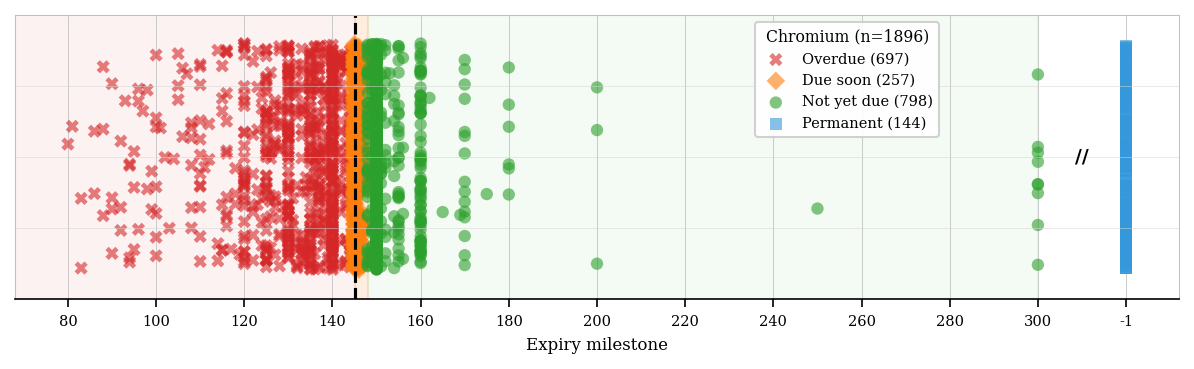

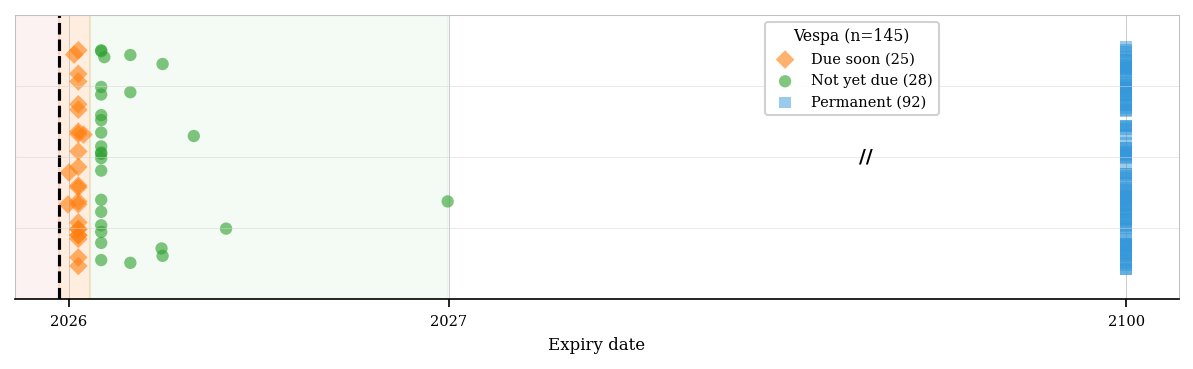

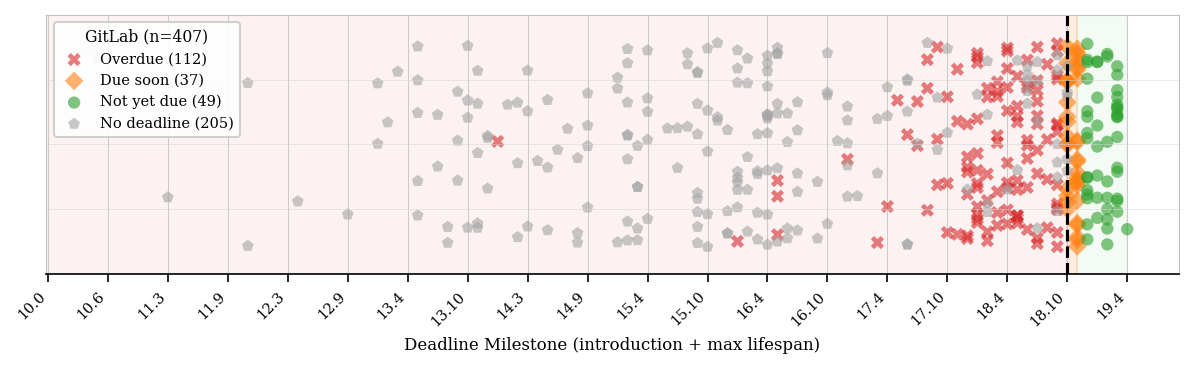

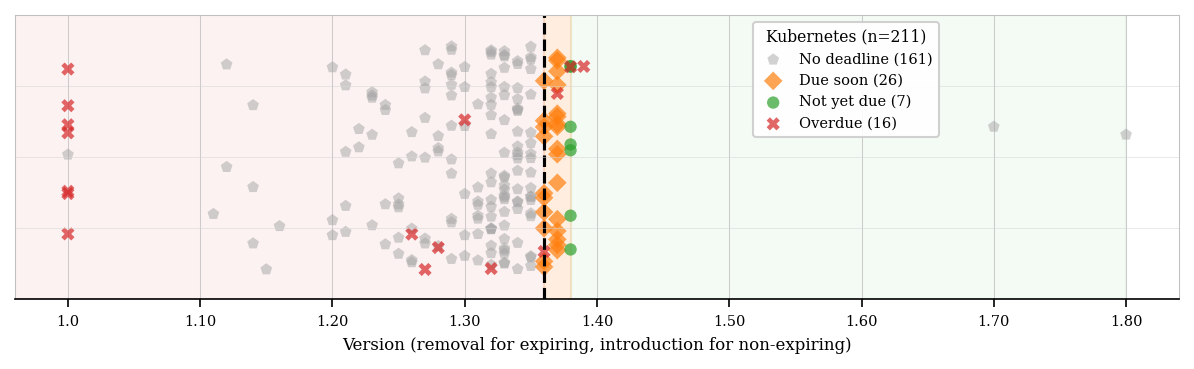

All individual charts saved to ../assets/strip-{chromium,vespa,gitlab,kubernetes}.{pdf,png}


In [7]:
# Individual strip plots for each system - publication-quality, one per figure
# Inspired by the GitLab strip plot dimensions (8" x 2.5") for readability
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})

np.random.seed(42)

color_map = {
    'Expired': '#d62728',
    'Expiring Soon': '#ff7f0e',
    'Active': '#2ca02c',
    'Never Expires': '#3498db',
    'No deadline': '#a5a5a5',
    'Without Expiration': '#9467bd'
}

marker_map = {
    'Expired': 'X',
    'Expiring Soon': 'D',
    'Active': 'o',
    'Never Expires': 's',
    'No deadline': 'p',
    'Without Expiration': 'p'
}

size_map = {
    'Expired': 40,
    'Expiring Soon': 40,
    'Active': 35,
    'Never Expires': 30,
    'No deadline': 35,
    'Without Expiration': 35
}

# Legend wording unified with the Sankey figure (Overdue / Due soon / Not yet due / Permanent)
DISP = {
    'Expired': 'Overdue',
    'Expiring Soon': 'Due soon',
    'Active': 'Not yet due',
    'Never Expires': 'Permanent',
    'No deadline': 'No deadline',
    'Without Expiration': 'No deadline',
}

def style_strip_ax(ax):
    """Clean strip-plot styling for paper."""
    ax.spines['bottom'].set_color('black')
    ax.spines['bottom'].set_linewidth(0.8)
    for side in ['top', 'left', 'right']:
        ax.spines[side].set_color('#c0c0c0')
        ax.spines[side].set_linewidth(0.5)
    ax.set_yticks([])
    ax.set_ylim(-0.5, 0.5)
    ax.tick_params(axis='x', direction='out', length=4, width=0.8)
    # Vertical grid lines
    ax.grid(axis='x', color='#c0c0c0', linestyle='-', linewidth=0.5, alpha=0.8)
    # Horizontal grid lines at y=0 and y=±0.25 for visual anchoring
    for yval in [-0.25, 0, 0.25]:
        ax.axhline(y=yval, color='#d5d5d5', linestyle='-', linewidth=0.4, alpha=0.6)
    ax.set_axisbelow(True)

def shade_regions(ax, ref, soon_end, right_end):
    """Light background bands: overdue (red) | due soon (orange) | not yet due (green)."""
    import matplotlib.dates as mdates
    def _num(v):
        return mdates.date2num(v) if hasattr(v, 'to_pydatetime') else v
    ref, soon_end, right_end = _num(ref), _num(soon_end), _num(right_end)
    x0, x1 = ax.get_xlim()
    ax.axvspan(x0, ref, color='#d62728', alpha=0.06, zorder=0)
    ax.axvspan(ref, soon_end, color='#ff7f0e', alpha=0.13, zorder=0)
    ax.axvspan(soon_end, right_end, color='#2ca02c', alpha=0.05, zorder=0)
    ax.set_xlim(x0, x1)

def scatter_cat(ax, x, status, s=None, alpha=0.6, label=None):
    """Scatter with random y-jitter."""
    if s is None:
        s = size_map[status]
    y = np.random.uniform(-0.4, 0.4, len(x))
    ax.scatter(x, y, c=color_map[status], marker=marker_map[status],
               edgecolors='none', s=s, alpha=alpha, label=label)

def parse_version_num(x):
    try:
        clean = ''.join(c for c in str(x) if c.isdigit() or c == '.')
        parts = clean.split('.')
        if len(parts) >= 2:
            return float(f"{parts[0]}.{parts[1]}")
        return float(parts[0])
    except:
        return None

# ============================================================
# (a) CHROMIUM - Individual Chart
# ============================================================
fig, ax = plt.subplots(figsize=(8, 2.5))

df_c = dfs['chromium'].copy()
df_c['has_expiration'] = df_c['has_expiration'].astype(str).str.lower() == 'true'
df_c['is_never_expire'] = df_c['is_never_expire'].astype(str).str.lower() == 'true'
df_c['expiry_milestone'] = pd.to_numeric(df_c['expiry_milestone'], errors='coerce')

df_with_ms = df_c[(df_c['has_expiration']) & (~df_c['is_never_expire'])].copy()
df_never = df_c[df_c['is_never_expire'] == True]

df_with_ms['exp_status'] = 'Active'
df_with_ms.loc[df_with_ms['expiry_milestone'] < current_milestone_ch, 'exp_status'] = 'Expired'
df_with_ms.loc[(df_with_ms['expiry_milestone'] >= current_milestone_ch) &
               (df_with_ms['expiry_milestone'] < current_milestone_ch + 3), 'exp_status'] = 'Expiring Soon'

for st in ['Expired', 'Expiring Soon', 'Active']:
    sub = df_with_ms[df_with_ms['exp_status'] == st]
    if len(sub) > 0:
        scatter_cat(ax, sub['expiry_milestone'].values, st, label=f'{DISP[st]} ({len(sub)})')

max_ms = df_with_ms['expiry_milestone'].max()
min_ms = df_with_ms['expiry_milestone'].min()

if len(df_never) > 0:
    never_x = max_ms + 20
    scatter_cat(ax, np.full(len(df_never), never_x), 'Never Expires',
                label=f'{DISP["Never Expires"]} ({len(df_never)})')
    ax.text(max_ms + 10, 0, '//', fontsize=9, ha='center', va='center', fontweight='bold')

ch_tick_start = int(min_ms // 20 * 20)
ch_tick_end = int(max_ms) + 20
ch_data_ticks = list(range(ch_tick_start, ch_tick_end, 20))
if len(df_never) > 0:
    ax.set_xticks(ch_data_ticks + [never_x])
    ax.set_xticklabels([str(t) for t in ch_data_ticks] + ['-1'])
else:
    ax.set_xticks(ch_data_ticks)

ax.axvline(x=current_milestone_ch, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Expiry milestone')
shade_regions(ax, current_milestone_ch, current_milestone_ch + 3, max_ms)
style_strip_ax(ax)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.0), fontsize=7, framealpha=0.9,
          title=f'Chromium (n={len(df_c)})', title_fontsize=7.5)

plt.tight_layout()
plt.savefig('../assets/strip-chromium.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-chromium.png', bbox_inches='tight')
plt.show()

# ============================================================
# (b) VESPA - Individual Chart
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 2.5))

df_v = dfs['vespa'].copy()
df_v['expires_at'] = pd.to_datetime(df_v['expires_at'], errors='coerce')
df_v['is_permanent'] = df_v['is_permanent'].astype(str).str.lower() == 'true'

df_v_exp = df_v[~df_v['is_permanent']].copy()
df_v_perm = df_v[df_v['is_permanent']].copy()

df_v_exp['exp_status'] = 'Active'
df_v_exp.loc[df_v_exp['expires_at'] < current_date, 'exp_status'] = 'Expired'
df_v_exp.loc[(df_v_exp['expires_at'] >= current_date) &
             (df_v_exp['expires_at'] < current_date + pd.Timedelta(days=30)), 'exp_status'] = 'Expiring Soon'

for st in ['Expired', 'Expiring Soon', 'Active']:
    sub = df_v_exp[df_v_exp['exp_status'] == st]
    if len(sub) > 0:
        y = np.random.uniform(-0.4, 0.4, len(sub))
        ax.scatter(sub['expires_at'], y, c=color_map[st], marker=marker_map[st],
                   edgecolors='none', s=size_map[st], alpha=0.6, label=f'{DISP[st]} ({len(sub)})')

if len(df_v_perm) > 0:
    if len(df_v_exp) > 0:
        last_exp_date = df_v_exp['expires_at'].max()
        first_exp_date = df_v_exp['expires_at'].min()
    else:
        last_exp_date = current_date
        first_exp_date = current_date - pd.Timedelta(days=365)

    min_visual_end = pd.Timestamp('2027-06-01')
    if last_exp_date < min_visual_end:
        last_exp_date = min_visual_end

    visual_gap = pd.Timedelta(days=500)
    perm_visual_date = last_exp_date + visual_gap

    y = np.random.uniform(-0.4, 0.4, len(df_v_perm))
    ax.scatter([perm_visual_date]*len(df_v_perm), y, c=color_map['Never Expires'],
               marker=marker_map['Never Expires'], edgecolors='none', s=size_map['Never Expires'],
               alpha=0.5, label=f'{DISP["Never Expires"]} ({len(df_v_perm)})')

    years = pd.date_range(start=first_exp_date, end=last_exp_date, freq='YS')
    if len(years) == 0 or years[-1].year < last_exp_date.year:
        years = years.union([pd.Timestamp(f"{last_exp_date.year}-01-01")])
    ticks = list(years) + [perm_visual_date]
    labels = [t.strftime('%Y') for t in ticks[:-1]] + ["2100"]
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels)

    break_pos = last_exp_date + (visual_gap / 2)
    ax.text(break_pos, 0, '//', fontsize=9, ha='center', va='center', fontweight='bold')

ax.axvline(x=current_date, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Expiry date')
shade_regions(ax, current_date, current_date + pd.Timedelta(days=30), df_v_exp['expires_at'].max())
style_strip_ax(ax)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.0), fontsize=7, framealpha=0.9,
          title=f'Vespa (n={len(df_v)})', title_fontsize=7.5)

plt.tight_layout()
plt.savefig('../assets/strip-vespa.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-vespa.png', bbox_inches='tight')
plt.show()

# ============================================================
# (c) GITLAB - Individual Chart
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 2.5))

df_gl_plot = df_gl.copy()
df_gl_plot = df_gl_plot[df_gl_plot['introduced_months'].notna()].copy()

def get_x_position(row):
    flag_type = row['flag_type']
    intro = row['introduced_months']
    lifespan = lifespan_map.get(flag_type, None)
    if lifespan is None:
        return intro
    return intro + lifespan

df_gl_plot['x_pos'] = df_gl_plot.apply(get_x_position, axis=1)

# GitLab's "no lifespan" flags have no deadline (not an explicit permanent), so show them grey
gl_disp = {'Never Expires': 'No deadline'}
for st in ['Expired', 'Expiring Soon', 'Active', 'Never Expires']:
    sub = df_gl_plot[df_gl_plot['expiration_status'] == st]
    if len(sub) > 0:
        disp = gl_disp.get(st, st)
        scatter_cat(ax, sub['x_pos'].values, disp, alpha=0.6,
                    label=f'{DISP.get(disp, disp)} ({len(sub)})')

ax.axvline(x=current_months, color='black', linestyle='--', linewidth=1.5)

all_x = df_gl_plot['x_pos'].dropna()
min_m = int(all_x.min())
max_m = int(all_x.max())
tick_positions = list(range(min_m - (min_m % 6), max_m + 6, 6))
tick_labels = [months_to_milestone(m) for m in tick_positions]
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right')

ax.set_xlabel('Deadline Milestone (introduction + max lifespan)')
shade_regions(ax, current_months, current_months + 1, df_gl_plot['x_pos'].max())
style_strip_ax(ax)
ax.legend(loc='upper left', fontsize=7, framealpha=0.9,
          title=f'GitLab (n={len(df_gl)})', title_fontsize=7.5)

plt.tight_layout()
plt.savefig('../assets/strip-gitlab.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-gitlab.png', bbox_inches='tight')
plt.show()

# ============================================================
# (d) KUBERNETES - Individual Chart
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 2.5))

df_k = dfs['kubernetes'].copy()
df_k['has_expiration'] = df_k['has_expiration'].astype(str).str.lower() == 'true'
df_k['removal_ver_num'] = df_k['removal_version'].apply(parse_version_num)
df_k['added_ver_num'] = df_k['version_added'].apply(parse_version_num)

is_deprecated = df_k['stage'] == 'Deprecated'
is_expired = df_k['has_expiration'] & (df_k['removal_ver_num'] < current_release_num)
df_k['is_stale'] = is_deprecated | is_expired

df_k_stale = df_k[df_k['is_stale']].copy()
df_k_not_stale = df_k[~df_k['is_stale']].copy()

df_k_stale['version_num'] = df_k_stale['removal_ver_num'].fillna(df_k_stale['added_ver_num'])
df_k_stale = df_k_stale.dropna(subset=['version_num'])

df_k_with_exp = df_k_not_stale[df_k_not_stale['has_expiration']].copy()
df_k_without_exp = df_k_not_stale[~df_k_not_stale['has_expiration']].copy()

df_k_with_exp['version_num'] = df_k_with_exp['removal_ver_num']
df_k_with_exp = df_k_with_exp.dropna(subset=['version_num'])
df_k_with_exp['exp_status'] = 'Active'
df_k_with_exp.loc[(df_k_with_exp['version_num'] >= current_release_num) &
                  (df_k_with_exp['version_num'] < round(current_release_num + 0.02, 2)), 'exp_status'] = 'Expiring Soon'

df_k_without_exp['version_num'] = df_k_without_exp['added_ver_num']
df_k_without_exp = df_k_without_exp.dropna(subset=['version_num'])

if len(df_k_without_exp) > 0:
    scatter_cat(ax, df_k_without_exp['version_num'].values, 'No deadline', alpha=0.5,
                label=f'{DISP["No deadline"]} ({len(df_k_without_exp)})')

for st in ['Expiring Soon', 'Active']:
    sub = df_k_with_exp[df_k_with_exp['exp_status'] == st]
    if len(sub) > 0:
        scatter_cat(ax, sub['version_num'].values, st, alpha=0.7,
                    label=f'{DISP[st]} ({len(sub)})')

if len(df_k_stale) > 0:
    scatter_cat(ax, df_k_stale['version_num'].values, 'Expired', alpha=0.7,
                label=f'{DISP["Expired"]} ({len(df_k_stale)})')

ax.axvline(current_release_num, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Version (removal for expiring, introduction for non-expiring)')

all_k8s_x = pd.concat([df_k_stale['version_num'], df_k_with_exp['version_num'],
                        df_k_without_exp['version_num']], ignore_index=True)
k8s_min = all_k8s_x.min()
k8s_max = all_k8s_x.max()
k8s_ticks = np.arange(int(k8s_min * 100) // 10 * 10 / 100,
                       k8s_max + 0.10, 0.10)
k8s_tick_labels = [f'{int(t)}.{int(round((t % 1)*100))}' for t in k8s_ticks]
ax.set_xticks(k8s_ticks)
ax.set_xticklabels(k8s_tick_labels)
shade_regions(ax, current_release_num, round(current_release_num + 0.02, 2), k8s_max)
style_strip_ax(ax)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.0), fontsize=7, framealpha=0.9,
          title=f'Kubernetes (n={len(df_k)})', title_fontsize=7.5)

plt.tight_layout()
plt.savefig('../assets/strip-kubernetes.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-kubernetes.png', bbox_inches='tight')
plt.show()

print("All individual charts saved to ../assets/strip-{chromium,vespa,gitlab,kubernetes}.{pdf,png}")


In [8]:
# Table 2: toggles, deadlines and overdue toggles per system at T0.
# `flows` is also used by the Sankey figure below.
def _n(s, v):
    return int((s == v).sum())

# Kubernetes: deprecated gates and gates without a removal version are counted apart
k_with = df_k[df_k['has_expiration']]
k_open = k_with[(k_with['stage'] != 'Deprecated') & k_with['removal_ver_num'].notna()]
k_over = int((k_open['removal_ver_num'] < current_release_num).sum())
k_soon = int(((k_open['removal_ver_num'] >= current_release_num) &
              (k_open['removal_ver_num'] < round(current_release_num + 0.02, 2))).sum())

flows = {
    'Chromium': {'total': len(df_c),
                 'over': _n(df_with_ms['exp_status'], 'Expired'), 'soon': _n(df_with_ms['exp_status'], 'Expiring Soon'),
                 'later': _n(df_with_ms['exp_status'], 'Active'), 'dep': 0,
                 'perm': len(df_never), 'none': len(df_c) - len(df_with_ms) - len(df_never)},
    'GitLab': {'total': len(df_gl),
               'over': _n(df_gl['expiration_status'], 'Expired'), 'soon': _n(df_gl['expiration_status'], 'Expiring Soon'),
               'later': _n(df_gl['expiration_status'], 'Active'), 'dep': 0,
               'perm': 0, 'none': int((~df_gl['flag_type'].isin(GL_TYPES_WITH_EXPIRATION)).sum())},
    'Kubernetes': {'total': len(df_k),
                   'over': k_over, 'soon': k_soon, 'later': len(k_open) - k_over - k_soon,
                   'dep': len(k_with) - len(k_open),
                   'perm': 0, 'none': len(df_k) - len(k_with)},
    'Vespa': {'total': len(df_v),
              'over': _n(df_v_exp['exp_status'], 'Expired'), 'soon': _n(df_v_exp['exp_status'], 'Expiring Soon'),
              'later': _n(df_v_exp['exp_status'], 'Active'), 'dep': 0,
              'perm': len(df_v_perm), 'none': 0},
}

rows = []
for name, f in flows.items():
    assert sum(f[k] for k in ('over', 'soon', 'later', 'dep', 'perm', 'none')) == f['total'], name
    with_dl = f['over'] + f['soon'] + f['later'] + f['dep']
    rows.append({'System': name, 'Toggles': f['total'], 'Permanent': f['perm'], 'No deadline': f['none'],
                 'With deadline': with_dl, 'Overdue': f['over'],
                 'Overdue (%)': round(100 * f['over'] / with_dl, 1) if with_dl else 0.0,
                 'Due soon': f['soon'], 'Not yet due': f['later']})
pd.DataFrame(rows).set_index('System')

,Toggles,Permanent,No deadline,With deadline,Overdue,Overdue (%),Due soon,Not yet due
System,,,,,,,,
Chromium,1896,144,0,1752,697,39.8,257,798
GitLab,407,0,209,198,112,56.6,37,49
Kubernetes,211,0,161,50,1,2.0,26,7
Vespa,145,92,0,53,0,0.0,25,28


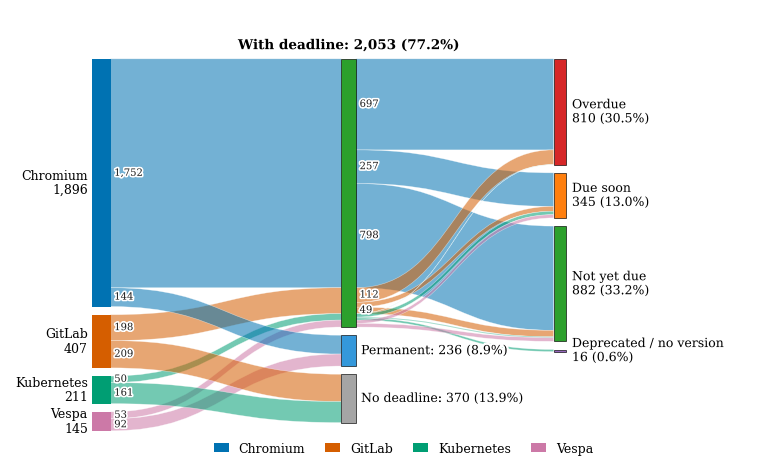

Total toggles: 2,659  (with deadline 2,053, 77.2%)
System       total   with   perm   none |   over   soon  later   dep
Chromium      1896   1752    144      0 |    697    257    798     0
GitLab         407    198      0    209 |    112     37     49     0
Kubernetes     211     50      0    161 |      1     26      7    16
Vespa          145     53     92      0 |      0     25     28     0
Chart saved to ../assets/rq1-rq2-sankey.pdf and .png


In [9]:
# Sankey (single-column, paper style): flows = system, category node bars = RQ1 split / RQ2 status.
# Light background, serif fonts, and the paper's status palette so it matches the other figures.
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle, Patch

SYS = ['Chromium', 'GitLab', 'Kubernetes', 'Vespa']
STATUSES = ['over', 'soon', 'later', 'dep']

with_sys = {s: sum(flows[s][k] for k in STATUSES) for s in SYS}
agg = {k: sum(flows[s][k] for s in SYS) for k in ('over', 'soon', 'later', 'dep', 'perm', 'none')}
total = sum(flows[s]['total'] for s in SYS)
with_total = sum(with_sys.values())

# System colours (flows) -- colourblind-friendly, kept away from the status hues
SYS_COL = {
    'Chromium':   '#0072B2',  # blue
    'GitLab':     '#D55E00',  # vermillion
    'Kubernetes': '#009E73',  # bluish green
    'Vespa':      '#CC79A7',  # pink
}
# Category colours (node bars) -- the paper's status / adoption palette
CAT_COL = {
    'with': '#2ca02c', 'perm': '#3498db', 'none': '#a5a5a5',   # RQ1: with / permanent / none
    'over': '#d62728', 'soon': '#ff7f0e', 'later': '#2ca02c', 'dep': '#9467bd',  # RQ2 statuses
}
CAT_LBL = {'with': 'With deadline', 'perm': 'Permanent', 'none': 'No deadline',
           'over': 'Overdue', 'soon': 'Due soon', 'later': 'Not yet due',
           'dep': 'Deprecated / no version'}

# Geometry for a single-column figure
X_SYS = (0.075, 0.100)
XM0, XM1 = 0.415, 0.435     # RQ1 node bar
XL0, XL1 = 0.705, 0.722     # RQ2 node bar
GAP = 0.022
unit = (1.0 - 3 * GAP) / total

stroke = [path_effects.withStroke(linewidth=2.2, foreground='white')]
nstroke = [path_effects.withStroke(linewidth=1.6, foreground='white')]
FLOW_LBL_MIN = 0.013        # only label bands at least this thick (so the number fits)

def band(ax, x0, x1, top0, bot0, top1, bot1, color, alpha=0.55):
    xm = (x0 + x1) / 2
    verts = [(x0, top0), (xm, top0), (xm, top1), (x1, top1),
             (x1, bot1), (xm, bot1), (xm, bot0), (x0, bot0), (x0, top0)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    ax.add_patch(PathPatch(Path(verts, codes), facecolor=color, edgecolor='white',
                           linewidth=0.25, alpha=alpha))

def flow_count(ax, x0, src_top, src_bot, val):
    """Small count placed just inside a band, at its (non-overlapping) source edge."""
    if (src_top - src_bot) >= FLOW_LBL_MIN:
        ax.text(x0 + 0.005, (src_top + src_bot) / 2, f"{val:,}", ha='left', va='center',
                fontsize=4.8, color='#1a1a1a', path_effects=nstroke)

def stack(order, top=1.0):
    pos, y = {}, top
    for key, val in order:
        h = val * unit
        pos[key] = (y, y - h)
        y -= h + GAP
    return pos

def subdiv(top, order):
    pos, y = {}, top
    for key, val in order:
        h = val * unit
        pos[key] = (y, y - h)
        y -= h
    return pos

def comp(key, s):
    return with_sys[s] if key == 'with' else flows[s][key]

with plt.rc_context({'font.family': 'serif', 'font.size': 6.5, 'savefig.dpi': 300, 'figure.dpi': 150}):
    fig, ax = plt.subplots(figsize=(6.3, 3.8))
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    sys_pos = stack([(s, flows[s]['total']) for s in SYS])
    rq1_pos = stack([('with', with_total), ('perm', agg['perm']), ('none', agg['none'])])
    rq2_pos = stack([(k, agg[k]) for k in STATUSES])

    # Stage 1: system -> RQ1
    sys_out = {s: subdiv(sys_pos[s][0], [('with', with_sys[s]),
                                         ('perm', flows[s]['perm']),
                                         ('none', flows[s]['none'])]) for s in SYS}
    rq1_in = {key: subdiv(rq1_pos[key][0], [(s, comp(key, s)) for s in SYS])
              for key in ('with', 'perm', 'none')}
    for key in ('with', 'perm', 'none'):
        for s in SYS:
            val = comp(key, s)
            if val <= 0:
                continue
            st, sb = sys_out[s][key]
            tt, tb = rq1_in[key][s]
            band(ax, X_SYS[1], XM0, st, sb, tt, tb, SYS_COL[s])
            flow_count(ax, X_SYS[1], st, sb, val)

    # Stage 2: RQ1 "with deadline" -> RQ2 statuses
    with_out, y = {}, rq1_pos['with'][0]
    for s in SYS:
        with_out[s] = subdiv(y, [(k, flows[s][k]) for k in STATUSES])
        y -= with_sys[s] * unit
    rq2_in = {k: subdiv(rq2_pos[k][0], [(s, flows[s][k]) for s in SYS]) for k in STATUSES}
    for s in SYS:
        for k in STATUSES:
            val = flows[s][k]
            if val <= 0:
                continue
            st, sb = with_out[s][k]
            tt, tb = rq2_in[k][s]
            band(ax, XM1, XL0, st, sb, tt, tb, SYS_COL[s])
            flow_count(ax, XM1, st, sb, val)

    # System source blocks + labels
    for s in SYS:
        t, b = sys_pos[s]
        ax.add_patch(Rectangle((X_SYS[0], b), X_SYS[1] - X_SYS[0], t - b,
                               facecolor=SYS_COL[s], edgecolor='none'))
        ax.text(X_SYS[0] - 0.006, (t + b) / 2, f"{s}\n{flows[s]['total']:,}",
                ha='right', va='center', fontsize=6, color='black', linespacing=1.15)

    # RQ1 category node bars + labels
    for key in ('with', 'perm', 'none'):
        t, b = rq1_pos[key]
        ax.add_patch(Rectangle((XM0, b), XM1 - XM0, t - b, facecolor=CAT_COL[key],
                               edgecolor='black', linewidth=0.3))
        v = with_total if key == 'with' else agg[key]
        if key == 'with':
            ax.text((XM0 + XM1) / 2, t + 0.018, f"{CAT_LBL[key]}: {v:,} ({v/total*100:.1f}%)",
                    ha='center', va='bottom', fontsize=6.5, fontweight='bold',
                    color='black', path_effects=stroke)
        else:
            ax.text(XM1 + 0.007, (t + b) / 2, f"{CAT_LBL[key]}: {v:,} ({v/total*100:.1f}%)",
                    ha='left', va='center', fontsize=6, color='black', path_effects=stroke)

    # RQ2 category node bars + labels
    for k in STATUSES:
        t, b = rq2_pos[k]
        ax.add_patch(Rectangle((XL0, b), XL1 - XL0, t - b, facecolor=CAT_COL[k],
                               edgecolor='black', linewidth=0.3))
        v = agg[k]
        ax.text(XL1 + 0.008, (t + b) / 2, f"{CAT_LBL[k]}\n{v:,} ({v/total*100:.1f}%)",
                ha='left', va='center', fontsize=6, color='black',
                linespacing=1.1, path_effects=stroke)

    # System legend (flow colour)
    handles = [Patch(facecolor=SYS_COL[s], label=s) for s in SYS]
    ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.03),
              ncol=4, frameon=False, fontsize=6, handlelength=1.2, columnspacing=1.6)

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.06, 1.12)
    ax.axis('off')

    fig.savefig('../assets/rq1-rq2-sankey.pdf', bbox_inches='tight')
    fig.savefig('../assets/rq1-rq2-sankey.png', bbox_inches='tight')
    plt.show()

print(f"Total toggles: {total:,}  (with deadline {with_total:,}, {with_total/total*100:.1f}%)")
print(f"{'System':11s} {'total':>6} {'with':>6} {'perm':>6} {'none':>6} | {'over':>6} {'soon':>6} {'later':>6} {'dep':>5}")
for s in SYS:
    f = flows[s]
    print(f"{s:11s} {f['total']:6d} {with_sys[s]:6d} {f['perm']:6d} {f['none']:6d} | "
          f"{f['over']:6d} {f['soon']:6d} {f['later']:6d} {f['dep']:5d}")
print("Chart saved to ../assets/rq1-rq2-sankey.pdf and .png")
